指数交易日: 2024-01-02 ~ 2026-10-29, 共682天
共35个换月区间

==== 表5：各策略收益指标 ====
       中证1000    IM多头    平值看涨 实值看涨(实值程度最高) 实值看涨(最小时间价值)
年化收益率   2.98%  15.52%  27.79%       10.15%       26.18%
年化波动率  28.59%  29.05%  32.96%       30.80%       25.15%
最大回撤   28.77%  27.55%  22.73%       26.15%       20.48%
夏普比率     0.03    0.47    0.78         0.26         0.96
卡玛比率     0.10    0.56    1.22         0.39         1.28

==== 每期选约记录 (行权价/开盘价; TV=最小时间价值合约的时间价值) ====
         entry           IM  F_open         atm      itm_max       itm_tv     TV
0   2024-01-02  IM2401.CCFX  5895.0   5900/91.2   5000/876.6   5200/670.8  -24.2
1   2024-01-22  IM2402.CCFX  5204.8  5200/150.0   4750/493.0   4750/493.0   38.2
2   2024-02-20  IM2403.CCFX  4922.2  4900/220.4  3850/1060.8   4100/788.8  -33.4
3   2024-03-18  IM2404.CCFX  5560.0  5600/146.0  3850/1753.0  3900/1638.6  -21.4
4   2024-04-22  IM2405.CCFX  5155.4  5200/154.6   4500/675.0   4650/514.6    9.2
5   2024-05-20  IM2406.CCFX  5533.2  5500/175.0  3800/1746.6  4

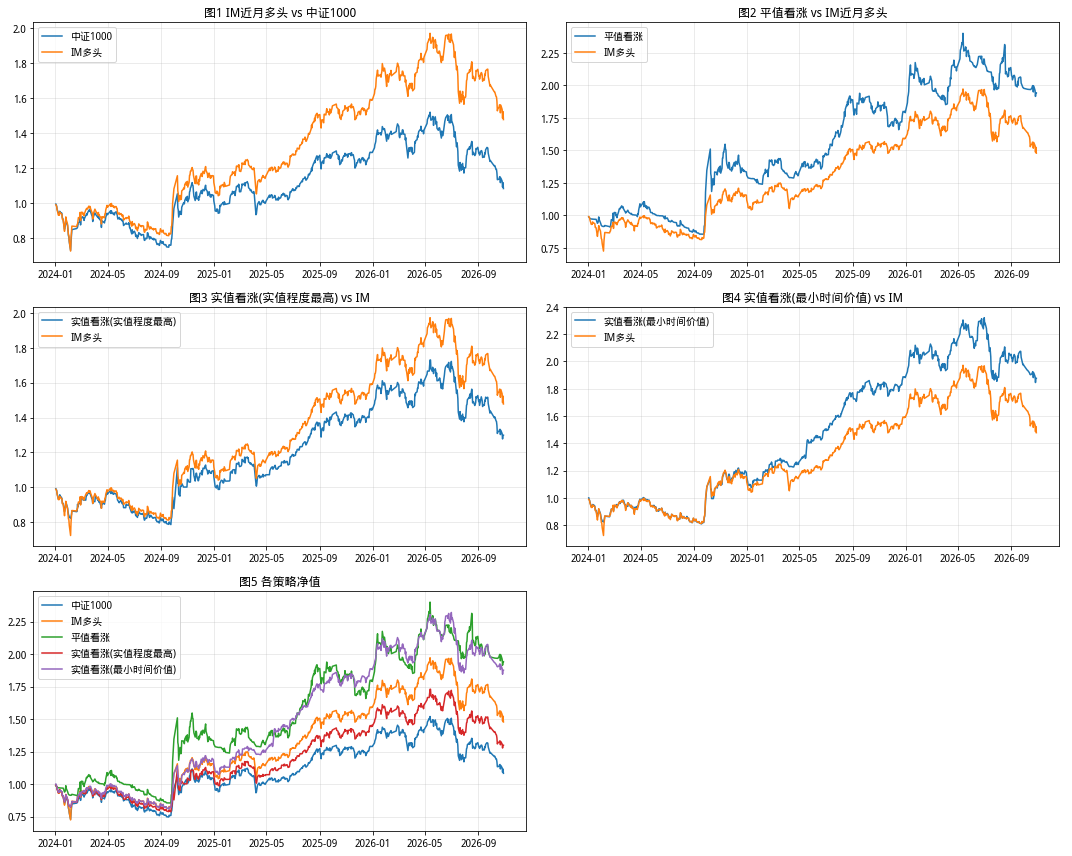


==== 大涨行情 : 2025-07-15 开盘建仓 IM2508.CCFX 持有到期 ====
交割结算价 S = 7104.66, 期货开仓价 F = 6375.00
策略                  合约  手数     开仓价   行权价  最大浮亏日     结算价    最大资金占用  最大占用比例        盈亏    研报盈亏
  期货多头         IM2508.CCFX   1  6375.0     /  07-15  6348.4  157681.6  12.37%  145932.0  145932
平值看涨多头  MO2508-C-6400.CCFX   4   147.0  6400      /     NaN   58800.0   4.61%  223064.0  223064
实值看涨多头  MO2508-C-5700.CCFX   2   658.6  5700      /     NaN  131720.0  10.33%  149212.0  149212

==== 大跌行情 : 2023-12-19 开盘建仓 IM2401.CCFX 持有到期 ====
交割结算价 S = 5322.72, 期货开仓价 F = 5826.00
策略                  合约  手数     开仓价   行权价  最大浮亏日     结算价    最大资金占用  最大占用比例        盈亏    研报盈亏
  期货多头         IM2401.CCFX   1  5826.0     /  01-18  5300.2  232364.8  19.94% -100656.0 -100656
平值看涨多头  MO2401-C-5800.CCFX   4   126.6  5800      /     NaN   50640.0   4.35%  -50640.0  -50640
实值看涨多头  MO2401-C-5400.CCFX   2   437.2  5400      /     NaN   87440.0   7.50%  -87440.0  -87440

==== 震荡行情 : 2025-09-17 开盘建仓 IM2510.CCFX 持有到期 ====
交割结算价 S = 723

In [1]:
# -*- coding: utf-8 -*-
"""
复现：华泰期货《期权吃贴水白皮书(一)》(2025-12-11)  —— 聚宽研究环境版
环境：Python 3.6.7 / numpy 1.19.5 / pandas 0.23.4（只用旧写法，不依赖 torch/scipy）
回测区间：2024-01-01 ~ 2026-12-20（超出数据末端的部分自动截断）
不写磁盘：所有数据直接在内存使用，结果全部 print（图用 plt.show 显示）

策略（均选取近月合约，开盘建仓，持有到期现金交割）
  1) 中证1000 买入持有
  2) IM 近月多头（不加杠杆）
  3) 平值看涨多头替代     1手IM : 4手MO，行权价取离同月IM开盘价最近
  4) 实值看涨(实值程度最高) 1手IM : 2手MO，行权价最低（需有成交）
  5) 实值看涨(最小时间价值) 1手IM : 2手MO，TimeValue = C - max(F-K, 0) 最小（K<F）
资金口径：初始净值1，按“IM 名义本金”配置，期权权利金以外的资金不计息（与研报一致）
到期结算：用 IM 到期日的 futures_sett_price（=指数交割结算价）
"""
from jqdata import *
from jqdata import finance
import numpy as np
import pandas as pd
import datetime
import warnings
warnings.filterwarnings('ignore')

try:
    query
except NameError:
    from jqdata import query

# ============================ 参数 ============================
START = '2024-01-01'
END = '2026-12-20'
INDEX_CODE = '000852.XSHG'
FUT_MULT = 200.0          # IM 合约乘数
OPT_MULT = 100.0          # MO 合约乘数
FUT_FEE = 0.3 / 10000     # 期货手续费(万0.3, 按名义金额, 开平各一次)
OPT_FEE = 20.0            # 期权手续费 元/张(开仓、到期行权各一次)
OPT_SLIP = 5.0 / 10000    # 期权滑点(万5, 作用于开仓价)
MIN_VOL = 1               # 选合约时要求开仓日有成交
RF = 0.02                 # 夏普无风险利率(用2%可对上研报数值)
PLOT = True
RUN_CASES = True

# 研报案例（不受 START/END 限制，沿用研报原日期）
CASES = [
    ('大涨行情', '2025-07-15', '2508', [145932, 223064, 149212]),
    ('大跌行情', '2023-12-19', '2401', [-100656, -50640, -87440]),
    ('震荡行情', '2025-09-17', '2510', [-32934, -83680, -31694]),
]


# ============================ 数据函数 ============================
def d2s(x):
    return pd.Timestamp(x).strftime('%Y-%m-%d')


def get_px(code, s, e, fields=('open', 'close', 'volume')):
    df = get_price(code, start_date=s, end_date=e, frequency='daily',
                   fields=list(fields), skip_paused=False)
    if df is None or len(df) == 0:
        return pd.DataFrame()
    df.index = pd.to_datetime(df.index)
    return df


def get_settle(code, s, e):
    """期货结算价序列(到期日=指数交割结算价)"""
    try:
        df = get_extras('futures_sett_price', [code], start_date=s, end_date=e, df=True)
        ser = df[code].dropna()
        ser.index = pd.to_datetime(ser.index)
        return ser
    except Exception as ex:
        print('get_extras 失败', code, ex)
        return pd.Series([])


def get_mo_calls(yymm):
    """某到期月的全部 MO 看涨合约资料"""
    q = query(opt.OPT_CONTRACT_INFO).filter(
        opt.OPT_CONTRACT_INFO.code.like('MO' + yymm + '-C-%'))
    df = opt.run_query(q)
    return df


def get_opt_day(codes, day):
    q = query(opt.OPT_DAILY_PRICE).filter(
        opt.OPT_DAILY_PRICE.code.in_(list(codes)),
        opt.OPT_DAILY_PRICE.date == d2s(day))
    return opt.run_query(q)


_hist_cache = {}


def get_opt_hist(code):
    if code in _hist_cache:
        return _hist_cache[code]
    q = query(opt.OPT_DAILY_PRICE).filter(
        opt.OPT_DAILY_PRICE.code == code).order_by(opt.OPT_DAILY_PRICE.date.asc())
    df = opt.run_query(q)
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
    _hist_cache[code] = df
    return df


def get_chain(yymm, day):
    """开仓日当天某月全部看涨期权(行权价+开盘价+成交量)"""
    info = get_mo_calls(yymm)
    if info is None or len(info) == 0:
        return None
    px = get_opt_day(info['code'].tolist(), day)
    if px is None or len(px) == 0:
        return None
    ch = px[['code', 'open', 'close', 'volume']].merge(
        info[['code', 'exercise_price']], on='code')
    ch = ch.rename(columns={'exercise_price': 'K'})
    ch['K'] = ch['K'].astype(float)
    return ch


def pick_options(chain, F):
    """返回 {'atm':row,'itm_max':row,'itm_tv':row}"""
    out = {}
    if chain is None:
        return out
    c = chain[(chain['open'] > 0) & (chain['volume'] >= MIN_VOL)].copy()
    if len(c) == 0:
        return out
    c['dist'] = (c['K'] - F).abs()
    out['atm'] = c.sort_values(['dist', 'K']).iloc[0]
    itm = c[c['K'] < F].copy()
    if len(itm) > 0:
        out['itm_max'] = itm.sort_values('K').iloc[0]
        itm['tv'] = itm['open'] - (F - itm['K'])
        out['itm_tv'] = itm.sort_values(['tv', 'K']).iloc[0]
    return out


def get_fut_margin_rate(code, day):
    try:
        q = query(finance.FUT_MARGIN).filter(
            finance.FUT_MARGIN.day == d2s(day), finance.FUT_MARGIN.code == code)
        df = finance.run_query(q)
        if len(df) > 0:
            v = float(df['specul_buy_margin_rate'].iloc[0])
            return v / 100.0 if v > 1 else v
    except Exception:
        pass
    return 0.12


# ============================ 绩效指标 ============================
def metrics(nv):
    nv = np.asarray(nv, dtype=float)
    r = nv[1:] / nv[:-1] - 1
    n = len(r)
    ann = nv[-1] ** (252.0 / n) - 1
    vol = r.std(ddof=1) * np.sqrt(252)
    mdd = (1 - nv / np.maximum.accumulate(nv)).max()
    sharpe = (ann - RF) / vol if vol > 0 else np.nan
    calmar = ann / mdd if mdd > 0 else np.nan
    return [ann, vol, mdd, sharpe, calmar]


def fmt_metrics(res):
    rows = ['年化收益率', '年化波动率', '最大回撤', '夏普比率', '卡玛比率']
    out = pd.DataFrame(index=rows)
    for k, v in res.items():
        out[k] = ['{:.2%}'.format(v[0]), '{:.2%}'.format(v[1]), '{:.2%}'.format(v[2]),
                  '{:.2f}'.format(v[3]), '{:.2f}'.format(v[4])]
    return out


# ============================ 长期回测 ============================
def backtest():
    end_eff = min(pd.Timestamp(END), pd.Timestamp(datetime.date.today()))
    ipx = get_px(INDEX_CODE, START, d2s(end_eff), fields=('open', 'close'))
    idx = ipx.index
    data_last = idx[-1]
    print('指数交易日: {} ~ {}, 共{}天'.format(d2s(idx[0]), d2s(data_last), len(idx)))

    ft = get_all_securities(['futures'])
    ft = ft[ft.index.str.startswith('IM') & ft.index.str.endswith('.CCFX')]
    ft = ft[~ft.index.str.contains('8888|9999')].copy()
    ft['end_ts'] = pd.to_datetime(ft['end_date'])
    ft = ft.sort_values('end_ts')

    # ---- 构造换月计划
    periods = []
    prev_end = None
    for code, row in ft.iterrows():
        last_td = row['end_ts']
        if last_td < idx[0]:
            continue
        if prev_end is None:
            entry = idx[idx >= pd.Timestamp(START)][0]
        else:
            after = idx[idx > prev_end]
            if len(after) == 0:
                break
            entry = after[0]
        if entry > data_last:
            break
        if entry > last_td:
            continue
        periods.append((code, entry, last_td))
        prev_end = last_td
        if last_td >= data_last:
            break
    print('共{}个换月区间'.format(len(periods)))

    names = {'fut': 'IM多头', 'atm': '平值看涨',
             'itm_max': '实值看涨(实值程度最高)', 'itm_tv': '实值看涨(最小时间价值)'}
    nav = {k: 1.0 for k in names}
    paths = {k: [] for k in names}
    ratio = {'atm': 2.0, 'itm_max': 1.0, 'itm_tv': 1.0}   # 1手IM对应 4/2/2 手MO => k=2/1/1
    log = []

    for code, entry, last_td in periods:
        yymm = code[2:6]
        end_day = min(last_td, data_last)
        days = idx[(idx >= entry) & (idx <= end_day)]
        closed = last_td <= data_last
        fpx = get_px(code, d2s(entry), d2s(end_day))
        if len(fpx) == 0 or entry not in fpx.index or not fpx.loc[entry, 'open'] > 0:
            print('跳过(无期货数据):', code, d2s(entry))
            for k in names:
                paths[k].append(pd.Series(nav[k], index=days))
            continue
        F0 = float(fpx.loc[entry, 'open'])
        closes = fpx['close'].reindex(days).fillna(method='ffill').fillna(F0)
        final_F = None
        if closed:
            st = get_settle(code, d2s(last_td), d2s(last_td))
            final_F = float(st.iloc[-1]) if len(st) > 0 else float(closes.iloc[-1])

        # --- 期货
        n0 = nav['fut']
        q = n0 / (F0 * FUT_MULT)
        fee_o = FUT_FEE * F0 * FUT_MULT * q
        p = n0 + q * FUT_MULT * (closes - F0) - fee_o
        if closed:
            p.iloc[-1] = n0 + q * FUT_MULT * (final_F - F0) - fee_o - FUT_FEE * final_F * FUT_MULT * q
        paths['fut'].append(p)
        nav['fut'] = float(p.iloc[-1])

        # --- 期权
        chain = get_chain(yymm, entry)
        picks = pick_options(chain, F0)
        rec = {'entry': d2s(entry), 'IM': code, 'F_open': F0}
        for k in ['atm', 'itm_max', 'itm_tv']:
            n0 = nav[k]
            if k not in picks:
                print('  {} 无可选合约, 本期空仓: {} {}'.format(names[k], code, d2s(entry)))
                paths[k].append(pd.Series(n0, index=days))
                continue
            r = picks[k]
            K = float(r['K'])
            ent = float(r['open']) * (1 + OPT_SLIP)
            lots = n0 * ratio[k] / (F0 * OPT_MULT)
            h = get_opt_hist(r['code'])
            oc = h['close'].reindex(days).fillna(method='ffill').fillna(float(r['close']))
            fee_o = OPT_FEE * lots
            p = n0 + lots * OPT_MULT * (oc - ent) - fee_o
            if closed:
                final = max(final_F - K, 0.0)
                p.iloc[-1] = n0 + lots * OPT_MULT * (final - ent) - fee_o - OPT_FEE * lots
            paths[k].append(p)
            nav[k] = float(p.iloc[-1])
            rec[k] = '{}/{:.1f}'.format(int(K), float(r['open']))
            if k == 'itm_tv':
                rec['TV'] = float(r['open']) - (F0 - K)
        log.append(rec)

    # ---- 汇总净值
    series = {}
    for k in names:
        series[names[k]] = pd.concat(paths[k])
    day0 = periods[0][1]
    idx2 = idx[idx >= day0]
    ci = ipx['close'].reindex(idx2)
    series['中证1000'] = ci / float(ipx.loc[day0, 'open'])
    navdf = pd.DataFrame(series).reindex(idx2)

    order = ['中证1000', 'IM多头', '平值看涨', '实值看涨(实值程度最高)', '实值看涨(最小时间价值)']
    res = {}
    for k in order:
        nv = np.r_[1.0, navdf[k].values]
        res[k] = metrics(nv)

    print('\n==== 表5：各策略收益指标 ====')
    print(fmt_metrics(res)[order].to_string())

    print('\n==== 每期选约记录 (行权价/开盘价; TV=最小时间价值合约的时间价值) ====')
    lg = pd.DataFrame(log)
    cols = [c for c in ['entry', 'IM', 'F_open', 'atm', 'itm_max', 'itm_tv', 'TV'] if c in lg.columns]
    print(lg[cols].to_string())

    print('\n==== 期末净值 ====')
    print(navdf.iloc[-1].to_string())
    print('\n==== 净值(每20个交易日抽样) ====')
    print(navdf.iloc[::20].round(4).to_string())

    if PLOT:
        try:
            import matplotlib.pyplot as plt
            plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
            plt.rcParams['axes.unicode_minus'] = False
            fig, axes = plt.subplots(3, 2, figsize=(15, 12))
            pairs = [('图1 IM近月多头 vs 中证1000', ['中证1000', 'IM多头']),
                     ('图2 平值看涨 vs IM近月多头', ['平值看涨', 'IM多头']),
                     ('图3 实值看涨(实值程度最高) vs IM', ['实值看涨(实值程度最高)', 'IM多头']),
                     ('图4 实值看涨(最小时间价值) vs IM', ['实值看涨(最小时间价值)', 'IM多头']),
                     ('图5 各策略净值', order)]
            for ax, (t, ks) in zip(axes.flatten(), pairs):
                for k in ks:
                    ax.plot(navdf.index, navdf[k].values, label=k)
                ax.set_title(t)
                ax.legend(loc='upper left')
                ax.grid(True, alpha=0.3)
            axes.flatten()[-1].axis('off')
            plt.tight_layout()
            plt.show()
        except Exception as ex:
            print('绘图失败:', ex)
    return navdf, ft


# ============================ 案例分析 ============================
def run_case(title, entry, yymm, ref, ft_all):
    code = 'IM' + yymm + '.CCFX'
    print('\n==== {} : {} 开盘建仓 {} 持有到期 ===='.format(title, entry, code))
    if code not in ft_all.index:
        print('无合约', code)
        return
    last_td = pd.Timestamp(ft_all.loc[code, 'end_date'])
    fpx = get_px(code, entry, d2s(last_td))
    et = pd.Timestamp(entry)
    if len(fpx) == 0 or et not in fpx.index:
        print('无期货数据')
        return
    F0 = float(fpx.loc[et, 'open'])
    settle = get_settle(code, entry, d2s(last_td))
    S = float(settle.iloc[-1])
    notional = F0 * FUT_MULT
    rows = []

    # 期货：最大占用 = 最大浮亏 + 保证金(按最大浮亏日结算价)
    loss = (F0 - settle) * FUT_MULT
    dmax = settle.idxmin()
    mr = get_fut_margin_rate(code, dmax)
    usage = max(float(loss[dmax]), 0.0) + mr * float(settle[dmax]) * FUT_MULT
    rows.append(['期货多头', code, 1, F0, '/', d2s(dmax)[5:], float(settle[dmax]),
                 usage, usage / notional, (S - F0) * FUT_MULT, ref[0]])

    chain = get_chain(yymm, entry)
    picks = pick_options(chain, F0)
    for k, nm, lots in [('atm', '平值看涨多头', 4), ('itm_tv', '实值看涨多头', 2)]:
        ref_pnl = ref[1] if k == 'atm' else ref[2]
        if k not in picks:
            rows.append([nm, '无', lots, np.nan, np.nan, '/', np.nan, np.nan, np.nan, np.nan, ref_pnl])
            continue
        r = picks[k]
        K = float(r['K'])
        c0 = float(r['open'])
        pnl = (max(S - K, 0.0) - c0) * lots * OPT_MULT
        usage = c0 * lots * OPT_MULT
        rows.append([nm, r['code'], lots, c0, K, '/', np.nan, usage, usage / notional, pnl, ref_pnl])
    out = pd.DataFrame(rows, columns=['策略', '合约', '手数', '开仓价', '行权价', '最大浮亏日',
                                       '结算价', '最大资金占用', '最大占用比例', '盈亏', '研报盈亏'])
    out['最大占用比例'] = out['最大占用比例'].map(lambda x: '{:.2%}'.format(x) if x == x else 'nan')
    print('交割结算价 S = {:.2f}, 期货开仓价 F = {:.2f}'.format(S, F0))
    print(out.to_string(index=False))


# ============================ 主程序 ============================
navdf, ft_all = backtest()
if RUN_CASES:
    ft_full = get_all_securities(['futures'])
    ft_full = ft_full[ft_full.index.str.startswith('IM') & ft_full.index.str.endswith('.CCFX')]
    ft_full = ft_full[~ft_full.index.str.contains('8888|9999')]
    for t, e, y, ref in CASES:
        try:
            run_case(t, e, y, ref, ft_full)
        except Exception as ex:
            print('案例 {} 失败: {}'.format(t, ex))
